In [ ]:
import pandas as pd
import torch

from rdkit import Chem
from matplotlib import pyplot as plt

from wombat.mpnn import visualize_all_activations
from wombat.mpnn import mol_to_torch
from wombat.visualisation import visualize_atom_importance_from_mol
from wombat.mpnn.gine_experiments import FluCarbGINE

from wombat.xai_methods import IGAttributionMethod, SaliencyAttributionMethod, GNNExplainerAttributionMethod, \
    InputXGradientAttributionMethod
from wombat.xai_methods.captum_attributions import ShapleyValueSamplingAttributionMethod
from wombat.xai_methods.subgraph_x_attributions import SubgraphXAttributionMethod

In [ ]:
# SMILES are the same for everyone, except for Shap and SGX running on a fraction of them
# Here, we care only about qualitative (so we just need SMILES) so we load a csv for partial results for Saliency

gine_results_positive = pd.read_csv(
    "../artifacts/FluCarbGINE/Saliency_positive_explainability_results.csv")
gine_results_negative = pd.read_csv(
    "../artifacts/FluCarbGINE/Saliency_negative_explainability_results.csv")

In [19]:
def show_multiple_attributions(smiles_list: list[str], attrib_shower_fn: callable):
    ncols = 3
    nrows = (len(smiles_list) // ncols) + (1 if len(smiles_list) % ncols != 0 else 0)

    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10 * ncols, 10 * nrows))

    for ax in axs.flatten():
        ax.axis("off")

    for smiles, ax in zip(smiles_list, axs.flatten()):
        img = attrib_shower_fn(smiles)

        ax.imshow(img)

    plt.suptitle(attrib_shower_fn.__name__, fontsize=30)

    plt.show()
    plt.close()


In [20]:
def show_attribution_ig(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    ig_explainer = IGAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
    )

    atom_importance, _ = ig_explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [21]:
def show_attribution_pge(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    pg_explainer = torch.load("../artifacts/FluCarbGINE/PG Explainer_explainer.pt",
                              weights_only=False)

    atom_importance, _ = pg_explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [22]:
def show_attribution_gnn_expl(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    gnn_explainer = GNNExplainerAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
    )

    atom_importance, _ = gnn_explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [23]:
def show_attribution_svs(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    svs_explainer = ShapleyValueSamplingAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
        n_samples=1000
    )

    atom_importance, _ = svs_explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [24]:
def show_attribution_saliency(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    saliency_explainer = SaliencyAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
    )

    atom_importance, _ = saliency_explainer.explain(x, edge_features, edge_index)

    print("SALIENCY ATOM IMPORTANCE")

    for i, atom_entries in enumerate(atom_importance):
        for j, entry in enumerate(atom_entries):
            if x[i][8] == 1 and entry != 0:
                print(f"Oxygen atom {i} is important! (entry {j} = {entry})")

    print("===================")

    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [25]:
def show_attribution_sgx(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    explainer = SubgraphXAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
    )

    atom_importance, _ = explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [26]:
def show_attribution_inputxgradient(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    explainer = InputXGradientAttributionMethod(
        model=model,
        model_smarts="",
        positive_smiles=[],  # Not used in this case, but required by the interface
        negative_smiles=[],
    )

    atom_importance, _ = explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().detach().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

In [27]:
def show_activations(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    _, activations = model(x, edge_features, edge_index, dump_activations=True)

    imgs = visualize_all_activations(
        mol,
        activations,
        length=1000,
    )

    return imgs[0]

In [ ]:
positive_smiles = gine_results_positive["SMILES"].sample(n=20, random_state=42).tolist()

show_multiple_attributions(positive_smiles, show_attribution_ig)
show_multiple_attributions(positive_smiles, show_attribution_saliency)
show_multiple_attributions(positive_smiles, show_attribution_pge)
show_multiple_attributions(positive_smiles, show_attribution_svs)
show_multiple_attributions(positive_smiles, show_attribution_gnn_expl)
show_multiple_attributions(positive_smiles, show_attribution_inputxgradient)
show_multiple_attributions(positive_smiles, show_attribution_sgx)
show_multiple_attributions(positive_smiles, show_activations)


In [16]:
def show_attribution_pge_small_train(smiles):
    model = FluCarbGINE()
    mol = Chem.MolFromSmiles(smiles)

    x, edge_index, edge_features = mol_to_torch(mol, add_hydrogen_ohe=True)

    pg_explainer = torch.load(
        "../artifacts/FluCarbGINE/PG Explainer_small_train.pt",
        weights_only=False)

    atom_importance, _ = pg_explainer.explain(x, edge_features, edge_index)
    atom_importance = torch.sum(torch.abs(atom_importance), dim=1).cpu().numpy().tolist()
    img = visualize_atom_importance_from_mol(
        mol,
        atom_importance,
        length=1000,
        precision=2
    )

    return img

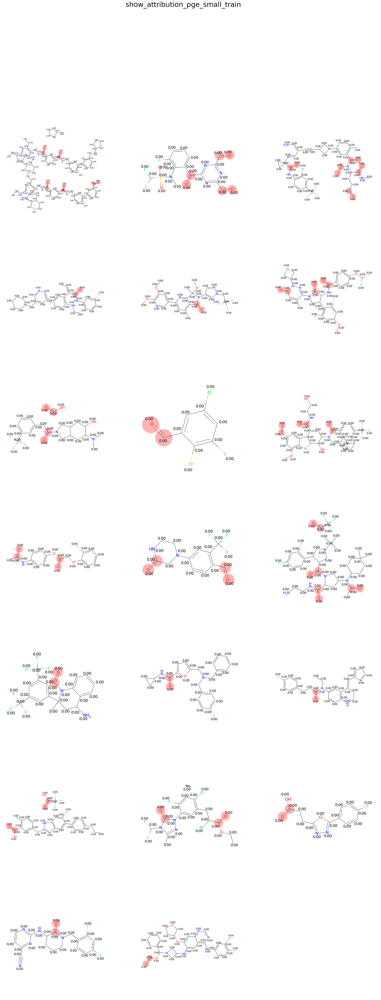

In [17]:
show_multiple_attributions(positive_smiles, show_attribution_pge_small_train)

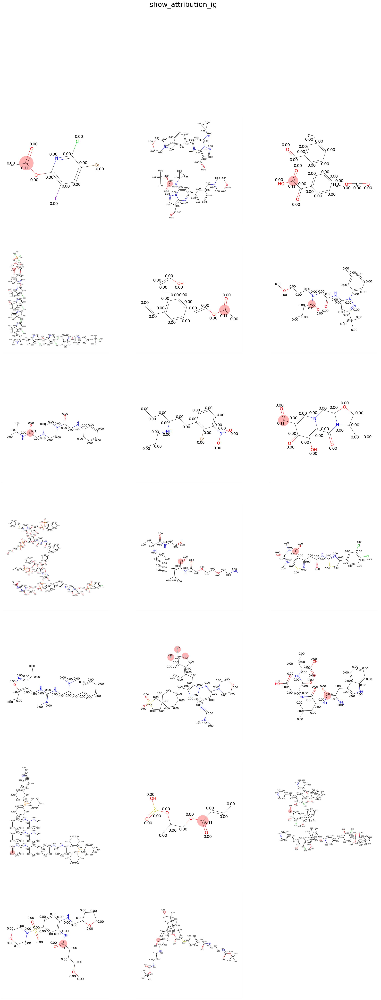

/home/dominik/MyStuff/bxaic2/.venv/lib/python3.12/site-packages/captum/attr/_core/saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)
/home/dominik/MyStuff/bxaic2/.venv/lib/python3.12/site-packages/captum/attr/_core/saliency.py:129: UserWarning: Input Tensor 1 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


SALIENCY ATOM IMPORTANCE
Oxygen atom 2 is important! (entry 0 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 1 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 2 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 3 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 4 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 5 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 6 = 0.8240628242492676)
Oxygen atom 2 is important! (entry 7 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 9 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 10 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 11 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 12 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 13 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 14 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 15 = 0.9156253933906555)
Oxygen atom 2 is important! (entry 16 = 0.9156253933906555)
Oxygen atom 2 is importa

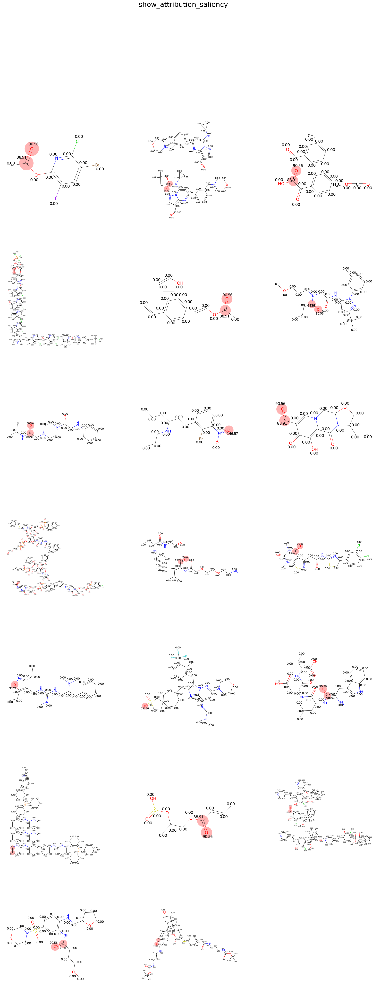

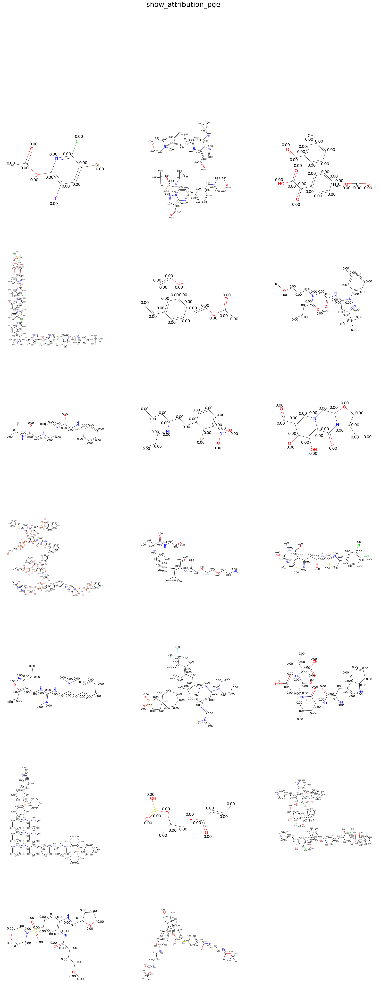

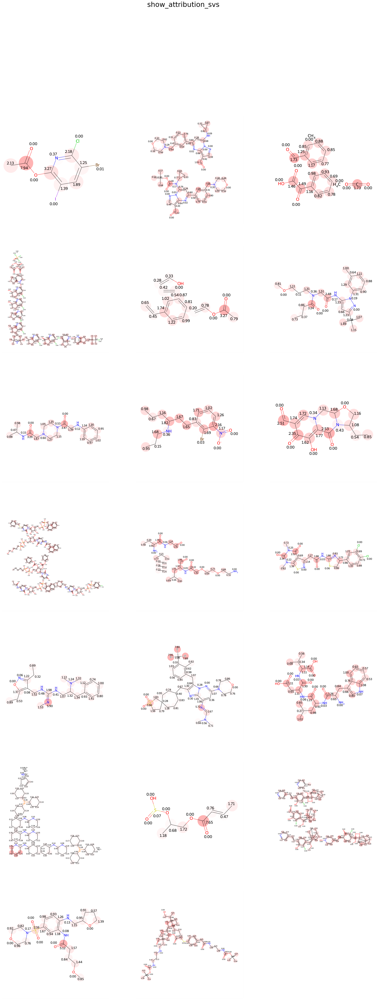

/home/dominik/MyStuff/bxaic2/.venv/lib/python3.12/site-packages/torch_geometric/explain/algorithm/base.py:192: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(y_hat, y)


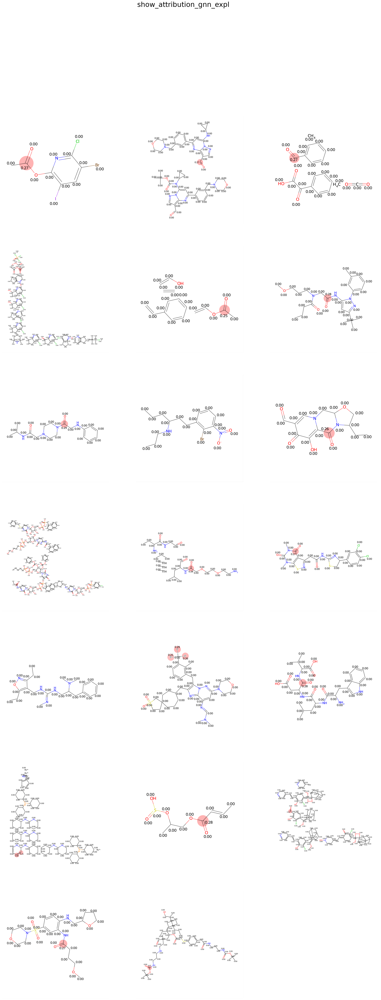

/home/dominik/MyStuff/bxaic2/.venv/lib/python3.12/site-packages/captum/attr/_core/input_x_gradient.py:118: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)
/home/dominik/MyStuff/bxaic2/.venv/lib/python3.12/site-packages/captum/attr/_core/input_x_gradient.py:118: UserWarning: Input Tensor 1 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


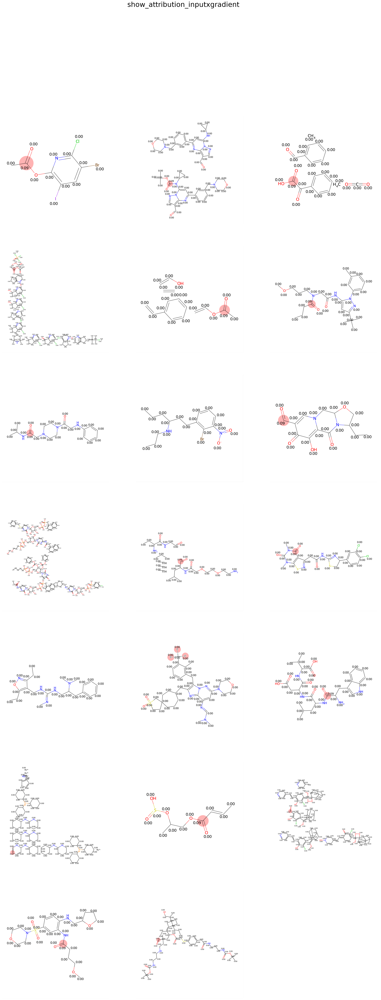

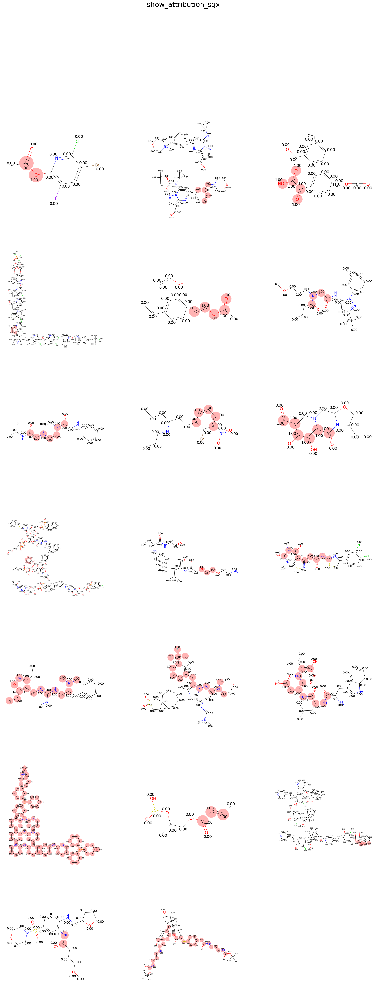

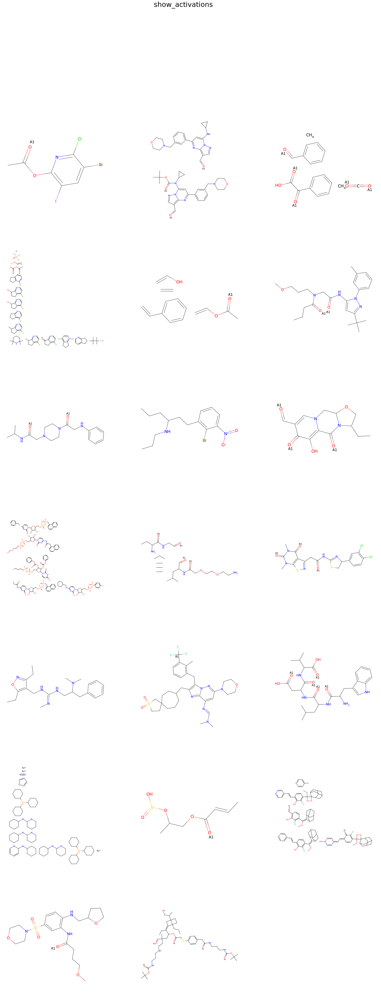

In [15]:
negative_smiles = gine_results_negative["SMILES"].sample(n=20, random_state=42).tolist()

show_multiple_attributions(negative_smiles, show_attribution_ig)
show_multiple_attributions(negative_smiles, show_attribution_saliency)
show_multiple_attributions(negative_smiles, show_attribution_pge)
show_multiple_attributions(negative_smiles, show_attribution_svs)
show_multiple_attributions(negative_smiles, show_attribution_gnn_expl)
show_multiple_attributions(negative_smiles, show_attribution_inputxgradient)
show_multiple_attributions(negative_smiles, show_attribution_sgx)
show_multiple_attributions(negative_smiles, show_activations)

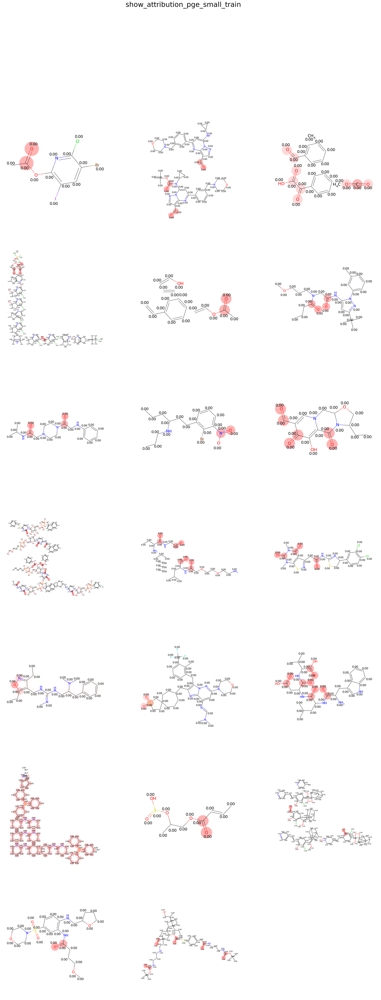

In [16]:
show_multiple_attributions(negative_smiles, show_attribution_pge_small_train)
